# CCT College Dublin: Assessment Cover Page

| | |
|---|---|
| Module Title |BSCH20 Sep23 FT Data Visualisation and Communication |
| Assessment Title | CA1 |
| Lecturer Name | Taufique Ahmed |
| Student Full Name | Lucas Alves Ribeiro |
| Student Number | 2023315 |
| Assessment Due Date | 07/11/2026 |
| Date of Submission | 07/11/2026 |
| Video Link | https://drive.google.com/file/d/1POvlIioG6w4MwG-sqoEZm-e4-IM2LF6O/view?usp=share_link |



**Declaration:** By submitting this assessment, I confirm that I have read the CCT policy on Academic Misconduct and understand the implications of submitting work that is not my own or does not appropriately reference material taken from a third party or other source. I declare it to be my own work and that all material from third parties has been appropriately referenced. I further confirm that this work has not previously been submitted for assessment by myself or someone else in CCT College Dublin or any other higher education institution.



# Visualising AI, Data Science and Software Development Employment in the USA

## 1. Introduction

This notebook explores employment in occupations related to **Artificial Intelligence (AI), Data Science and Software Development** in the United States. The main dataset is the **Occupational Employment and Wage Statistics (OEWS) "All data" file for May 2023**, published by the U.S. Bureau of Labor Statistics (BLS, 2024). It contains employment counts and wage estimates for every occupation, at national, state, metropolitan and industry level.

**Questions this notebook answers**

1. How many people work in AI related occupations, and how does that compare with software development? *(Visualisation 1)*
2. How much do these occupations pay, and how wide is the pay range inside each one? *(Visualisation 2)*
3. Is there a relationship between the size of an occupation and its pay? *(Visualisation 3)*
4. Where in the USA are AI related jobs concentrated? *(Visualisations 4 and 6)*
5. Which industries employ Data Scientists? *(Visualisation 5)*
6. **Challenge:** how did AI related employment and pay change from 2019 to 2023? *(Visualisations 7, 8 and 9)*

**How "AI employment" is defined here.** The Standard Occupational Classification (SOC) used by the BLS has no single "AI Engineer" code. AI work is spread across several occupations, so this notebook uses a group of occupations as a proxy, split into three categories that are used with the same colour in every chart:

| Category | Occupations (SOC code) | Why |
|---|---|---|
| **AI & Data Science** | Computer and Information Research Scientists (15-1221), Data Scientists (15-2051), Statisticians (15-2041), Operations Research Analysts (15-2031) | Roles that build models, machine learning systems and analytical methods. The BLS describes research scientists as working on areas such as machine learning and AI. |
| **Software Development** | Software Developers (15-1252), Software QA Analysts and Testers (15-1253), Web Developers (15-1254) | Roles that build and deploy software, including AI products. |
| **Supporting Tech** | Computer Systems Analysts (15-1211), Information Security Analysts (15-1212), Database Architects (15-1243), Computer and Information Systems Managers (11-3021) | Roles that design the data infrastructure and manage the teams around AI and software. |

## 2. Setup and data preparation

The libraries used are **pandas** for data handling, and **matplotlib** and **seaborn** for the charts. A fixed colour palette is defined once so that each category keeps the same colour in every chart. The palette was chosen to stay distinguishable for people with colour vision deficiency.

In [133]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Consistent style for every chart
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85",
    "axes.labelcolor": "#3d3d3a",
    "xtick.color": "#3d3d3a",
    "ytick.color": "#3d3d3a",
    "axes.grid": False,
    "grid.color": "#e6e5e0",
    "legend.frameon": False,
})

# Colour per category (colour-blind safe palette, fixed order)
CAT_COLOURS = {
    "AI & Data Science":    "#2a78d6",   # blue
    "Software Development": "#eb6834",   # orange
    "Supporting Tech":      "#1baf7a",   # aqua
}
GREY = "#8a8a85"
INK = "#3d3d3a"

In [134]:
# Load the May 2023 OEWS "All data" file (about 413,000 rows, takes around a minute)
raw = pd.read_excel("all_data_M_2023.xlsx", sheet_name="All May 2023 data")
print("Rows, columns:", raw.shape)
raw.head(3)

Rows, columns: (413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN


**Cleaning.** The BLS uses special symbols instead of numbers in some cells (see the "Field Descriptions" sheet):

* `*` wage estimate not available
* `**` employment estimate not available
* `#` wage equal to or greater than **$239,200 per year** (the published top limit)

These symbols are converted to missing values (`NaN`) so that the numeric columns can be used in calculations. For `#` a flag is kept, because it means "very high pay", not "unknown".

In [135]:
df = raw.copy()
df.columns = df.columns.str.upper()

num_cols = ["TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "PCT_TOTAL", "A_MEAN",
            "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"]

TOP_CODE = 239200   # value represented by '#'
df["A_PCT90_TOPCODED"] = df["A_PCT90"].astype(str).str.strip().eq("#")
df["A_PCT75_TOPCODED"] = df["A_PCT75"].astype(str).str.strip().eq("#")

for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")   # '*', '**', '#' -> NaN

# Focus occupations and their category
OCCS = {
    "15-1221": ("Computer & Info Research Scientists", "AI & Data Science"),
    "15-2051": ("Data Scientists",                     "AI & Data Science"),
    "15-2041": ("Statisticians",                       "AI & Data Science"),
    "15-2031": ("Operations Research Analysts",        "AI & Data Science"),
    "15-1252": ("Software Developers",                 "Software Development"),
    "15-1253": ("Software QA Analysts & Testers",      "Software Development"),
    "15-1254": ("Web Developers",                      "Software Development"),
    "15-1211": ("Computer Systems Analysts",           "Supporting Tech"),
    "15-1212": ("Information Security Analysts",       "Supporting Tech"),
    "15-1243": ("Database Architects",                 "Supporting Tech"),
    "11-3021": ("Computer & IS Managers",              "Supporting Tech"),
}

# National, cross-industry estimates (one row per occupation for the whole USA)
national = df[(df["AREA_TYPE"] == 1) & (df["I_GROUP"] == "cross-industry")]
all_occ = national[national["OCC_CODE"] == "00-0000"].iloc[0]

nat = national[national["OCC_CODE"].isin(OCCS)].copy()
nat["Occupation"] = nat["OCC_CODE"].map(lambda c: OCCS[c][0])
nat["Category"]   = nat["OCC_CODE"].map(lambda c: OCCS[c][1])

print(f"All occupations in the USA (May 2023): {all_occ['TOT_EMP']:,.0f} jobs, "
      f"median annual wage ${all_occ['A_MEDIAN']:,.0f}")
nat[["OCC_CODE", "Occupation", "Category", "TOT_EMP", "A_MEDIAN", "A_MEAN"]] \
    .sort_values("TOT_EMP", ascending=False).reset_index(drop=True)

All occupations in the USA (May 2023): 151,853,870 jobs, median annual wage $48,060


,OCC_CODE,Occupation,Category,TOT_EMP,A_MEDIAN,A_MEAN
0,15-1252,Software Developers,Software Development,1656880.0,132270.0,138110.0
1,11-3021,Computer & IS Managers,Supporting Tech,592600.0,169510.0,180720.0
2,15-1211,Computer Systems Analysts,Supporting Tech,498810.0,103800.0,110800.0
3,15-1253,Software QA Analysts & Testers,Software Development,203040.0,101800.0,108460.0
4,15-2051,Data Scientists,AI & Data Science,192710.0,108020.0,119040.0
5,15-1212,Information Security Analysts,Supporting Tech,175350.0,120360.0,124740.0
6,15-2031,Operations Research Analysts,AI & Data Science,117880.0,83640.0,95600.0
7,15-1254,Web Developers,Software Development,85350.0,84960.0,95570.0
8,15-1243,Database Architects,Supporting Tech,59920.0,134700.0,137030.0
9,15-1221,Computer & Info Research Scientists,AI & Data Science,35210.0,145080.0,157160.0


## 3. Visualisations of the May 2023 data

### Visualisation 1: Employment by occupation (horizontal bar chart)

**Objective:** *comparison.* Compare how many people work in each AI, data and software occupation in the USA, and see how big the AI & Data Science group is next to software development.

**Why this chart:** the data is one **categorical** variable (occupation) and one **numeric** variable (employment). A bar chart is the clearest way to compare magnitudes because the eye compares bar lengths very accurately. Bars are **horizontal** so that the long occupation names can be read without rotating them, and they are **sorted** so the ranking is visible at once. Colour shows the category.

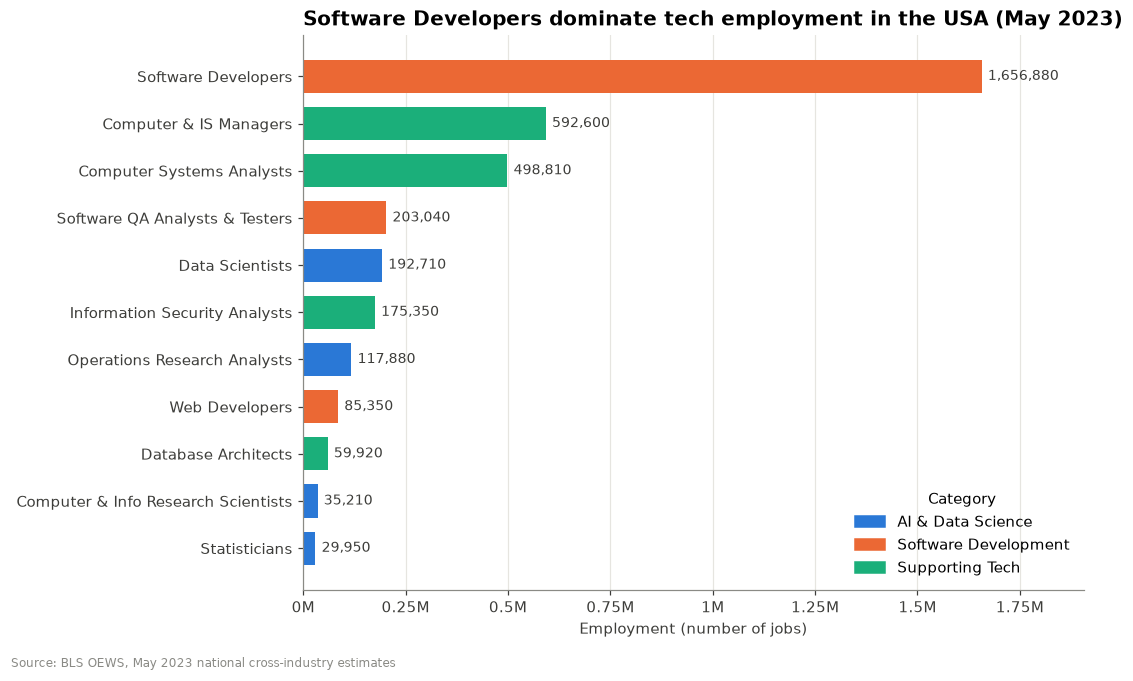

Category
Software Development    1,945,270
Supporting Tech         1,326,680
AI & Data Science         375,750


In [136]:
v1 = nat.sort_values("TOT_EMP")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(v1["Occupation"], v1["TOT_EMP"],
               color=v1["Category"].map(CAT_COLOURS), height=0.7)

for bar, val in zip(bars, v1["TOT_EMP"]):
    ax.text(bar.get_width() + 15000, bar.get_y() + bar.get_height() / 2,
            f"{val:,.0f}", va="center", fontsize=9, color=INK)

ax.xaxis.set_major_locator(mtick.MultipleLocator(250000))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:g}M"))
ax.set_xlim(0, v1["TOT_EMP"].max() * 1.15)
ax.set_xlabel("Employment (number of jobs)")
ax.set_title("Software Developers dominate tech employment in the USA (May 2023)")
ax.grid(axis="x")
ax.set_axisbelow(True)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CAT_COLOURS.values()]
ax.legend(handles, CAT_COLOURS.keys(), loc="lower right", title="Category")
fig.text(0.01, -0.02, "Source: BLS OEWS, May 2023 national cross-industry estimates", fontsize=8, color=GREY)
plt.tight_layout()
plt.show()

totals = nat.groupby("Category")["TOT_EMP"].sum().sort_values(ascending=False)
print((totals.map("{:,.0f}".format)).to_string())

**What I learned about AI employment:**

* Every occupation in the chart pays well above the median of all US jobs (**$48,060**). Even the lowest paid 10% of most of these roles earn close to or above that national median.
* Among the AI roles, **Computer and Information Research Scientists** have the highest median pay of the non managerial roles (**about $145,000**), and their 90th percentile reaches about **$233,000**. Specialist AI research skills are paid at a premium.
* **Data Scientists** have a median of about **$108,000**, lower than Software Developers (about **$132,000**). So data science is a well paid entry into AI, but at the national level it does not pay more than software engineering.
* The boxes are wide. For Data Scientists the 90th percentile is about **three times** the 10th percentile, which suggests that experience, seniority and location make a big difference to pay in AI related careers.

### Visualisation 3: Size of occupation versus median pay (scatter plot)

**Objective:** *investigation of a relationship.* Check whether bigger occupations pay more or less, and find which occupations combine high pay with a small number of workers (a sign of scarce, specialised skills).

**Why this chart:** both variables are **numeric** (employment and median wage), and a scatter plot is the standard chart for showing the relationship between two numeric variables. Employment ranges from about 30,000 to 1.6 million, so the x axis uses a **logarithmic scale**. Without it, ten of the eleven points would be squeezed together on the left. Each point is labelled because there are only eleven occupations.

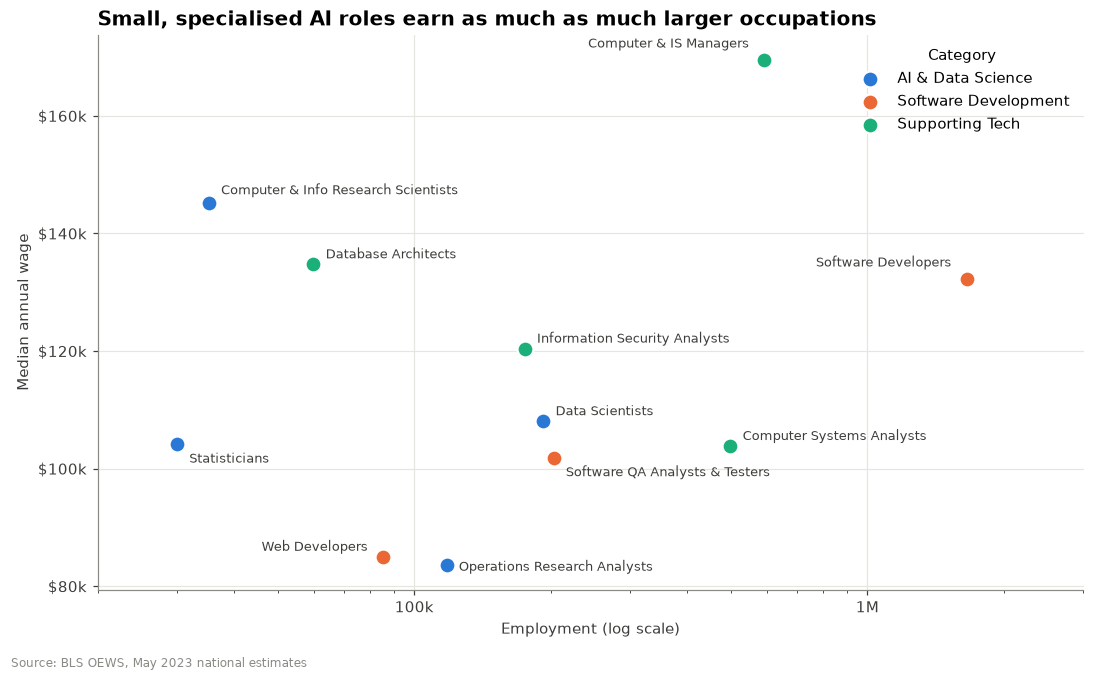

Correlation between log(employment) and median wage: 0.24


In [137]:
fig, ax = plt.subplots(figsize=(10, 6))
for cat, g in nat.groupby("Category"):
    ax.scatter(g["TOT_EMP"], g["A_MEDIAN"], s=110, color=CAT_COLOURS[cat],
               edgecolor="white", linewidth=1.5, label=cat, zorder=3)

offsets = {"Computer & Info Research Scientists": (8, 6), "Statisticians": (8, -12),
           "Database Architects": (8, 4), "Computer & IS Managers": (-10, 8),
           "Web Developers": (-10, 4), "Information Security Analysts": (8, 4),
           "Software QA Analysts & Testers": (8, -12), "Operations Research Analysts": (8, -4),
           "Software Developers": (-10, 8), "Data Scientists": (8, 4),
           "Computer Systems Analysts": (8, 4)}
for r in nat.itertuples():
    dx, dy = offsets.get(r.Occupation, (8, 4))
    ax.annotate(r.Occupation, (r.TOT_EMP, r.A_MEDIAN), xytext=(dx, dy),
                textcoords="offset points", fontsize=8.5, color=INK,
                ha="right" if dx < 0 else "left")

ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:g}M" if x >= 1e6 else f"{x/1000:,.0f}k"))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, _: f"${y/1000:.0f}k"))
ax.set_xlabel("Employment (log scale)")
ax.set_ylabel("Median annual wage")
ax.set_xlim(20000, 3e6)
ax.set_title("Small, specialised AI roles earn as much as much larger occupations")
ax.grid(True); ax.set_axisbelow(True)
ax.legend(title="Category", loc="upper right")
fig.text(0.01, -0.02, "Source: BLS OEWS, May 2023 national estimates", fontsize=8, color=GREY)
plt.tight_layout()
plt.show()

corr = np.corrcoef(np.log10(nat["TOT_EMP"]), nat["A_MEDIAN"])[0, 1]
print(f"Correlation between log(employment) and median wage: {corr:.2f}")

**What I learned about AI employment:**

* There is **no strong link** between the size of an occupation and its pay. The correlation is weak, so a role does not pay more just because it is in high demand overall.
* **Computer and Information Research Scientists** sit in the top left corner: very few workers but some of the highest pay. This is the typical pattern of a **scarce, specialised skill**, which fits the idea that advanced AI research talent is hard to find.
* **Data Scientists** and **Statisticians** sit in the middle. They are larger than research scientists and still well paid, which makes data science the most accessible route into AI work.
* **Software Developers** are both the largest and among the best paid groups, showing that general software skills remain extremely valuable in the AI era.

### Visualisation 4: Geographic concentration by state (heatmap of location quotients)

**Objective:** *comparison across two categorical dimensions.* Find which states have a higher than normal concentration of AI and software jobs.

**Why this chart:** the data is a **matrix**: states on one axis, occupations on the other, and one numeric value in each cell. A heatmap shows a matrix like this in a single view and makes patterns visible through colour. The value used is the **location quotient (LQ)**. LQ = 1 means the occupation's share of jobs in that state equals the national share, LQ = 2 means it is twice as concentrated. Because LQ has a natural middle point (1), a **diverging** colour scale is used: grey at 1, orange for above average, blue for below average. The exact values are written in each cell so the chart does not depend on colour alone. The 15 states shown are those with the most jobs across these six occupations.

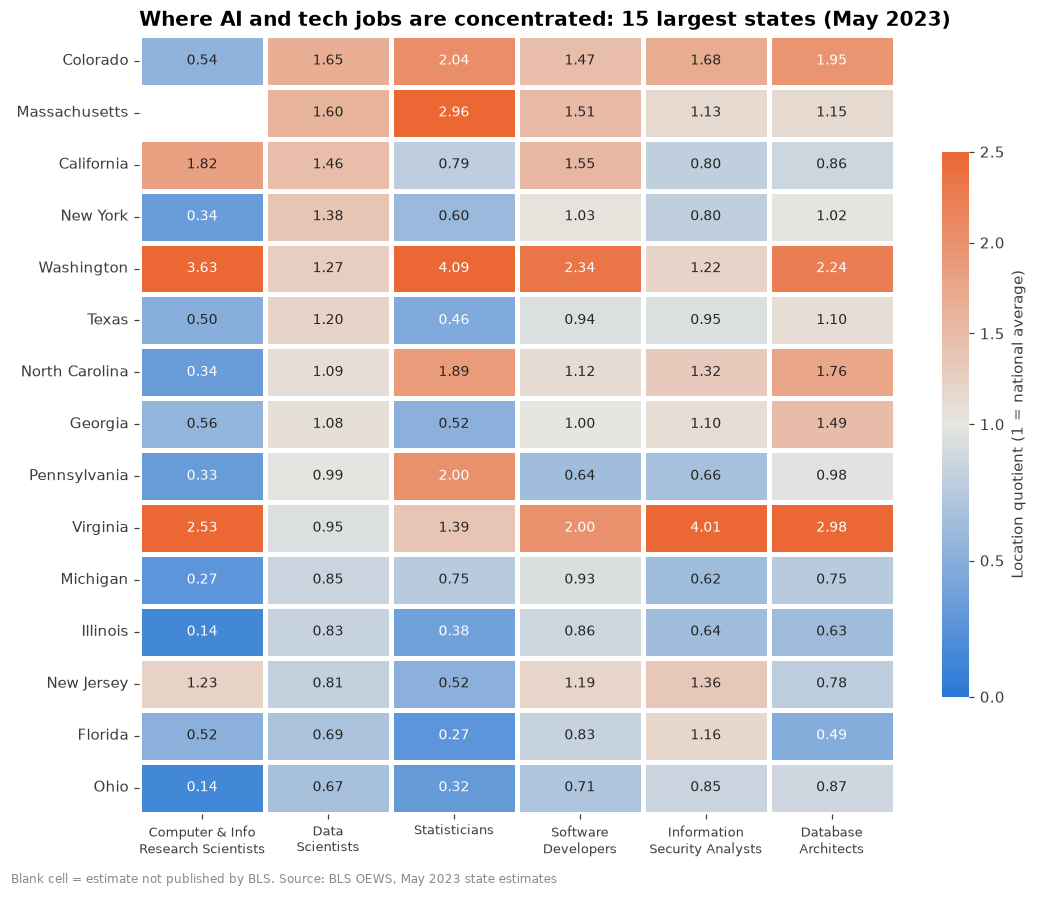

In [138]:
states = df[(df["AREA_TYPE"] == 2) & (df["OCC_CODE"].isin(OCCS))].copy()
states["Occupation"] = states["OCC_CODE"].map(lambda c: OCCS[c][0])

heat_occs = ["Computer & Info Research Scientists", "Data Scientists", "Statisticians",
             "Software Developers", "Information Security Analysts", "Database Architects"]
st = states[states["Occupation"].isin(heat_occs)]
top_states = st.groupby("AREA_TITLE")["TOT_EMP"].sum().nlargest(15).index

lq = (st[st["AREA_TITLE"].isin(top_states)]
      .pivot_table(index="AREA_TITLE", columns="Occupation", values="LOC_QUOTIENT")
      [heat_occs])
lq = lq.loc[lq["Data Scientists"].sort_values(ascending=False).index]

cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#e6e5e0", "#eb6834"])
norm = TwoSlopeNorm(vmin=0, vcenter=1, vmax=2.5)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(lq, annot=True, fmt=".2f", cmap=cmap, norm=norm, linewidths=2, linecolor="white",
            cbar_kws={"label": "Location quotient (1 = national average)", "shrink": 0.7},
            annot_kws={"fontsize": 9}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
wrap = {"Computer & Info Research Scientists": "Computer & Info\nResearch Scientists", "Software Developers": "Software\nDevelopers",
        "Information Security Analysts": "Information\nSecurity Analysts", "Database Architects": "Database\nArchitects",
        "Data Scientists": "Data\nScientists"}
ax.set_xticklabels([wrap.get(t.get_text(), t.get_text()) for t in ax.get_xticklabels()], rotation=0, fontsize=8.5)
ax.set_title("Where AI and tech jobs are concentrated: 15 largest states (May 2023)")
fig.text(0.01, -0.01, "Blank cell = estimate not published by BLS. Source: BLS OEWS, May 2023 state estimates",
         fontsize=8, color=GREY)
plt.tight_layout()
plt.show()

**What I learned about AI employment:**

* AI work is **geographically concentrated**. **Washington state** (home of large cloud and AI companies) stands out, with location quotients of **3.6** for Computer and Information Research Scientists, **4.1** for Statisticians and **2.3** for Software Developers. **Colorado**, **Massachusetts** and **California** are above average for almost every role, especially Data Scientists.
* **Virginia** has very high values for research scientists (**2.5**), information security analysts (**4.0**) and database architects (**3.0**). This is likely linked to federal government, defence and data centre activity near Washington DC, which shows that AI employment is not only a private technology sector story.
* Large states such as **Florida**, **Ohio** and **Illinois** have many jobs in absolute numbers but are **below the national average** (blue) for most AI roles. A big population does not automatically mean a high concentration of AI work.

### Visualisation 5: Data Scientists by industry (donut chart)

**Objective:** *composition (part to whole).* Show which industries employ Data Scientists, the largest AI & Data Science occupation.

**Why this chart:** the question is about **shares of a total**, which is the one job pie and donut charts do well. To keep it readable, only the five largest industry sectors are shown separately and the rest are grouped into "Other", because a pie with many thin slices is hard to read. The donut version leaves space in the centre for the total, and each slice is labelled with its percentage.

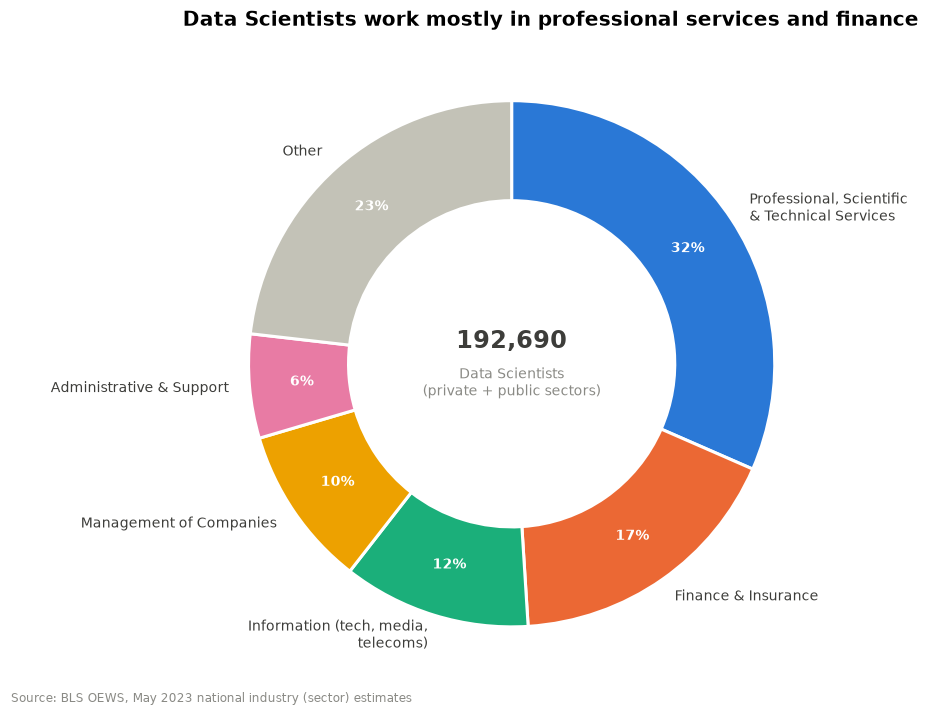

NAICS_TITLE
Professional, Scientific, and Technical Services                            31.6
Finance and Insurance                                                       17.4
Information                                                                 11.5
Management of Companies and Enterprises                                      9.9
Administrative and Support and Waste Management and Remediation Services     6.4
Health Care and Social Assistance                                            5.0
Manufacturing                                                                4.3
Educational Services                                                         3.6


In [139]:
ds_ind = df[(df["AREA_TYPE"] == 1) & (df["I_GROUP"] == "sector") & (df["OCC_CODE"] == "15-2051")]
ds_ind = ds_ind.groupby("NAICS_TITLE")["TOT_EMP"].sum().sort_values(ascending=False)

short = {
    "Professional, Scientific, and Technical Services": "Professional, Scientific\n& Technical Services",
    "Finance and Insurance": "Finance & Insurance",
    "Information": "Information (tech, media,\ntelecoms)",
    "Management of Companies and Enterprises": "Management of Companies",
    "Administrative and Support and Waste Management and Remediation Services": "Administrative & Support",
}
top5 = ds_ind.head(5)
pie_data = pd.concat([top5, pd.Series({"Other": ds_ind.iloc[5:].sum()})])
labels = [short.get(i, i) for i in pie_data.index]
colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#c3c2b7"]

fig, ax = plt.subplots(figsize=(9, 6.5))
wedges, texts, autotexts = ax.pie(
    pie_data, labels=labels, colors=colours, startangle=90, counterclock=False,
    autopct="%1.0f%%", pctdistance=0.8, labeldistance=1.08,
    wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2),
    textprops=dict(fontsize=9, color=INK))
for t in autotexts:
    t.set_color("white"); t.set_fontweight("bold")
ax.text(0, 0.06, f"{pie_data.sum():,.0f}", ha="center", fontsize=16, fontweight="bold", color=INK)
ax.text(0, -0.12, "Data Scientists\n(private + public sectors)", ha="center", fontsize=9, color=GREY)
ax.set_title("Data Scientists work mostly in professional services and finance")
fig.text(0.01, 0.01, "Source: BLS OEWS, May 2023 national industry (sector) estimates", fontsize=8, color=GREY)
plt.tight_layout()
plt.show()

print((ds_ind / ds_ind.sum() * 100).round(1).head(8).to_string())

**What I learned about AI employment:**

* About one third of Data Scientists work in **Professional, Scientific and Technical Services**, which includes consulting firms, computer systems design companies and research and development services. Much AI and data work is done by **specialist service companies** for other businesses.
* **Finance and Insurance** is the second biggest employer (about **17%**). Banks and insurers use data science heavily for risk, fraud detection and pricing.
* The **Information** sector (software publishers, internet and telecoms companies) is only about **12%**. So data science is **not limited to "tech companies"**. It is spread across the whole economy, which is good news for someone looking for a data career in any industry.

### Visualisation 6: Top metropolitan areas for Data Scientists (lollipop chart)

**Objective:** *ranking.* Identify the cities (metropolitan areas) where Data Scientists make up the highest share of local jobs.

**Why this chart:** this is a ranking of one numeric variable across many categories. A lollipop chart works like a bar chart but uses less ink, which keeps a long ranking clean and easy to read. The measure is **jobs per 1,000 jobs** instead of total employment, so that small cities can be compared fairly with big ones. Areas with fewer than 500 Data Scientists are excluded to avoid unreliable estimates. A dashed line shows the national average for comparison.

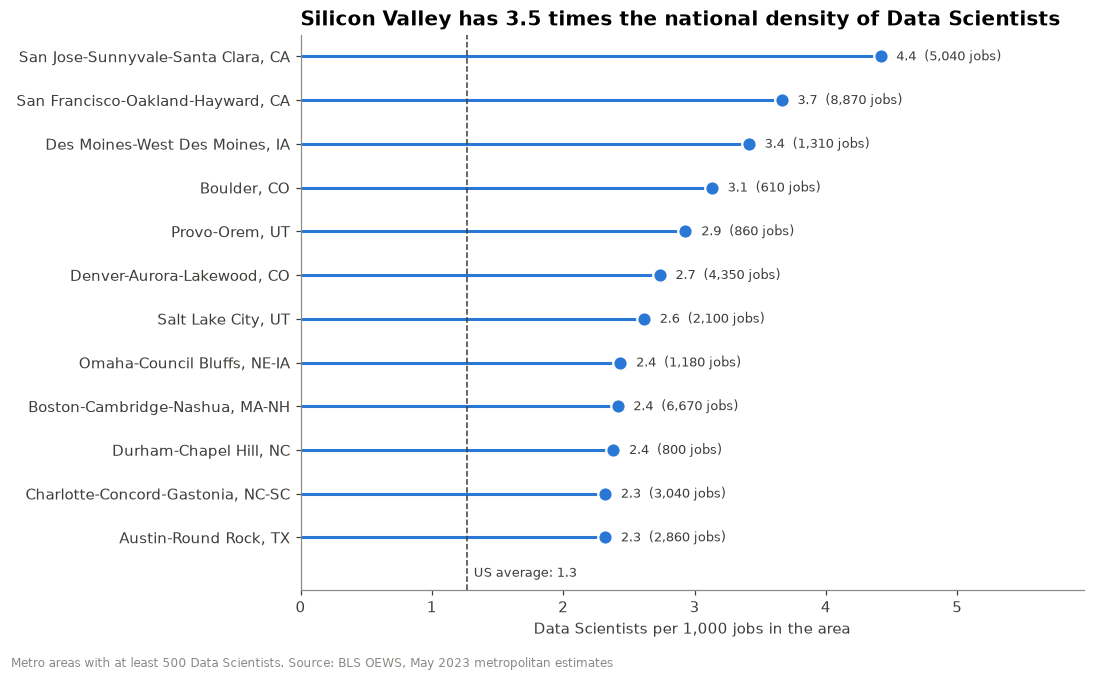

In [140]:
msa = df[(df["AREA_TYPE"] == 4) & (df["OCC_CODE"] == "15-2051")].copy()
msa = msa[msa["TOT_EMP"] >= 500].nlargest(12, "JOBS_1000").sort_values("JOBS_1000")
nat_rate = nat.loc[nat["OCC_CODE"] == "15-2051", "TOT_EMP"].iloc[0] / all_occ["TOT_EMP"] * 1000

fig, ax = plt.subplots(figsize=(10, 6))
ax.hlines(msa["AREA_TITLE"], 0, msa["JOBS_1000"], color=CAT_COLOURS["AI & Data Science"], linewidth=2)
ax.scatter(msa["JOBS_1000"], msa["AREA_TITLE"], s=90, color=CAT_COLOURS["AI & Data Science"],
           edgecolor="white", linewidth=1.5, zorder=3)
for r in msa.itertuples():
    ax.text(r.JOBS_1000 + 0.12, r.AREA_TITLE, f"{r.JOBS_1000:.1f}  ({r.TOT_EMP:,.0f} jobs)",
            va="center", fontsize=8.5, color=INK)

ax.axvline(nat_rate, color=INK, linestyle="--", linewidth=1)
ax.text(nat_rate + 0.05, -0.9, f"US average: {nat_rate:.1f}", fontsize=8.5, color=INK)
ax.set_xlim(0, msa["JOBS_1000"].max() * 1.35)
ax.set_ylim(-1.2, len(msa) - 0.5)
ax.set_xlabel("Data Scientists per 1,000 jobs in the area")
ax.set_title("Silicon Valley has 3.5 times the national density of Data Scientists")
fig.text(0.01, -0.02, "Metro areas with at least 500 Data Scientists. Source: BLS OEWS, May 2023 metropolitan estimates",
         fontsize=8, color=GREY)
plt.tight_layout()
plt.show()

**What I learned about AI employment:**

* **San Jose (Silicon Valley)** and **San Francisco** lead clearly, with about **4.4** and **3.7** Data Scientists per 1,000 jobs, around three times the US average of about **1.3**. The heart of the US AI industry is still the Bay Area.
* Some less obvious cities appear in the top twelve, such as **Des Moines (Iowa)**, a major insurance and financial services centre, and **Provo and Salt Lake City (Utah)**. This connects with Visualisation 5: finance and insurance create AI and data jobs outside traditional tech hubs.
* **Boston, Austin, Denver, Boulder, Durham and Charlotte** also have high concentrations, which shows a group of "secondary" AI hubs growing beyond California.

## 4. Challenge: AI employment trends over time (2019 to 2023)

### 4.1 Additional datasets

To study trends, the national estimates for **May 2019, 2020, 2021 and 2022** were taken from the same BLS OEWS tables page (https://www.bls.gov/oes/tables.htm), using the national tables for each year (BLS, 2020, 2021, 2022, 2023). The national employment and mean annual wage of the relevant occupations were collected into the file `bls_oews_national_2019_2022.csv`, which records the source page of each row. The **2023** values are taken directly from the main dataset loaded above, so both sources are combined.

### 4.2 An important data issue: the 2018 SOC change

The BLS moved to a new occupation classification (2018 SOC) gradually. In the **2019 and 2020** files some new occupations were still published as **combined "hybrid" codes**:

| 2019 and 2020 code | Equivalent from 2021 onwards |
|---|---|
| 15-2098 Data Scientists and Mathematical Science Occupations, All Other | 15-2051 Data Scientists + 15-2099 Math Science, All Other |
| 15-1256 Software Developers and Software QA Analysts and Testers | 15-1252 Software Developers + 15-1253 Software QA Analysts and Testers |

To compare years fairly, the 2021 to 2023 codes are **added together** to match the 2019 and 2020 definitions. The mean wage of a combined group is calculated as an employment weighted average. Even after this, part of the growth of Data Scientists between 2019 and 2021 comes from the classification change itself (some data scientists were still recorded under other codes during the transition). For that reason 2019 and 2020 are drawn with dashed lines, and the most reliable comparison is **2021 to 2023**, when the definitions are identical.

In [141]:
hist = pd.read_csv("bls_oews_national_2019_2022.csv")

# 2023 values for the same codes, taken from the main dataset
codes_needed = hist["occ_code"].unique().tolist() + ["15-1252", "15-1253", "15-2051", "15-2099"]
y23 = national[national["OCC_CODE"].isin(codes_needed)][["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN"]]
y23.columns = ["occ_code", "occ_title", "tot_emp", "a_mean"]
y23["year"] = 2023
y23["source"] = "all_data_M_2023.xlsx"

trend_raw = pd.concat([hist, y23], ignore_index=True)

# Harmonised groups (codes valid in each year)
GROUPS = {
    "Data Scientists*":                    ["15-2098", "15-2051", "15-2099"],
    "Computer & Info Research Scientists": ["15-1221"],
    "Statisticians":                       ["15-2041"],
    "Software Developers & QA*":           ["15-1256", "15-1252", "15-1253"],
    "Computer & Maths occupations (all)":  ["15-0000"],
    "All occupations":                     ["00-0000"],
}
rows = []
for name, codes in GROUPS.items():
    g = trend_raw[trend_raw["occ_code"].isin(codes)].copy()
    g["wage_x_emp"] = g["tot_emp"] * g["a_mean"]
    agg = g.groupby("year").agg(tot_emp=("tot_emp", "sum"), wage_x_emp=("wage_x_emp", "sum"))
    agg["a_mean"] = agg["wage_x_emp"] / agg["tot_emp"]
    agg["group"] = name
    rows.append(agg.reset_index()[["group", "year", "tot_emp", "a_mean"]])
trend = pd.concat(rows, ignore_index=True)

emp_table = trend.pivot(index="group", columns="year", values="tot_emp").loc[list(GROUPS)]
emp_table["Change 2021 to 2023"] = (emp_table[2023] / emp_table[2021] - 1).map("{:+.1%}".format)
emp_table

year,2019,2020,2021,2022,2023,Change 2021 to 2023
group,,,,,,
Data Scientists*,30810.0,59680.0,109950.0,163470.0,197030.0,+79.2%
Computer & Info Research Scientists,30780.0,30220.0,30840.0,33780.0,35210.0,+14.2%
Statisticians,39090.0,38860.0,31370.0,30780.0,29950.0,-4.5%
Software Developers & QA*,1406870.0,1476800.0,1554300.0,1731210.0,1859920.0,+19.7%
Computer & Maths occupations (all),4552880.0,4587700.0,4654750.0,5003910.0,5177400.0,+11.2%
All occupations,146875480.0,139099570.0,140886310.0,147886000.0,151853870.0,+7.8%


### Visualisation 7: Employment trend for each AI occupation (small multiple line charts)

**Objective:** *change over time.* Show how employment in each AI related occupation evolved from 2019 to 2023 and compare it with the whole US labour market.

**Why this chart:** **line charts** are the standard choice for a numeric variable over time, because the slope of the line shows the direction and speed of change. The occupations have very different sizes (from about 30,000 to 1.8 million workers), so one shared axis would flatten the small ones into a straight line. Instead the chart uses **small multiples**: one panel per group, each with its own scale, all with the same layout. The 2019 to 2021 segment is dashed to mark the classification change explained above, and each panel shows the like for like change from 2021 to 2023.

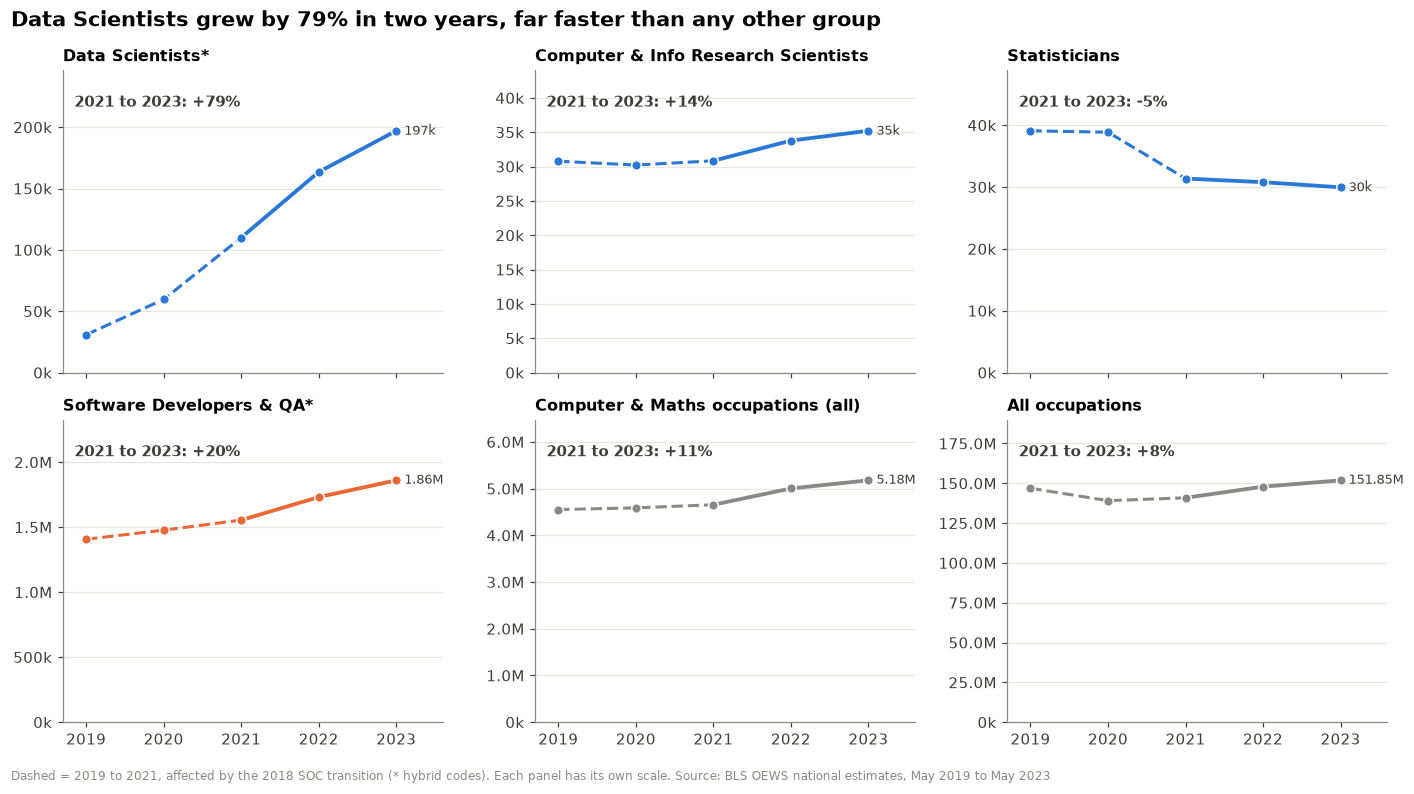

In [142]:
panels = ["Data Scientists*", "Computer & Info Research Scientists", "Statisticians",
          "Software Developers & QA*", "Computer & Maths occupations (all)", "All occupations"]
panel_colour = {"Data Scientists*": CAT_COLOURS["AI & Data Science"],
                "Computer & Info Research Scientists": CAT_COLOURS["AI & Data Science"],
                "Statisticians": CAT_COLOURS["AI & Data Science"],
                "Software Developers & QA*": CAT_COLOURS["Software Development"],
                "Computer & Maths occupations (all)": GREY, "All occupations": GREY}

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, name in zip(axes.flat, panels):
    t = trend[trend["group"] == name].set_index("year")["tot_emp"]
    c = panel_colour[name]
    ax.plot(t.loc[2019:2021].index, t.loc[2019:2021], color=c, linewidth=2, linestyle="--")
    ax.plot(t.loc[2021:2023].index, t.loc[2021:2023], color=c, linewidth=2.5)
    ax.scatter(t.index, t.values, color=c, s=40, zorder=3, edgecolor="white")
    change = t[2023] / t[2021] - 1
    ax.set_title(name, fontsize=10.5)
    ax.text(0.03, 0.88, f"2021 to 2023: {change:+.0%}", transform=ax.transAxes,
            fontsize=10, fontweight="bold", color=INK)
    ax.text(2023, t[2023], f"  {t[2023]/1e6:.2f}M" if t[2023] >= 1e6 else f"  {t[2023]/1000:,.0f}k", va="center", fontsize=8.5, color=INK)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(
        lambda y, _: f"{y/1e6:.1f}M" if y >= 1e6 else f"{y/1000:.0f}k"))
    ax.set_ylim(0, t.max() * 1.25)
    ax.set_xlim(2018.7, 2023.6)
    ax.set_xticks([2019, 2020, 2021, 2022, 2023])
    ax.grid(axis="y"); ax.set_axisbelow(True)

fig.suptitle("Data Scientists grew by 79% in two years, far faster than any other group",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, -0.02, "Dashed = 2019 to 2021, affected by the 2018 SOC transition (* hybrid codes). "
         "Each panel has its own scale. Source: BLS OEWS national estimates, May 2019 to May 2023",
         fontsize=8, color=GREY)
plt.tight_layout()
plt.show()

**What I learned about AI employment over time:**

* **Data Scientists** are the clear growth story. On a like for like basis, employment rose from about **110,000 in 2021 to 197,000 in 2023, an increase of about 79% in only two years**. This matches the boom in data driven and AI products in that period.
* **Software Developers and QA** grew by about **20%** and **Computer & Info Research Scientists** by about **14%**. Both grew much faster than the total US labour market, which grew by about **8%** in the same period (partly recovery from COVID 19).
* **Statisticians** stayed almost flat and actually **fell** compared with 2019. One possible explanation is that new analytical jobs are now advertised as "data scientist" instead of "statistician", so the growth is moving to the newer job title.
* The **2020** values for all occupations show the COVID 19 drop, but the technology occupations did **not** fall in 2020, which shows how resilient these jobs were during the pandemic.

### Visualisation 8: Change in mean pay from 2019 to 2023 (dumbbell chart)

**Objective:** *comparison of change between two points in time.* Compare how much average pay increased in each AI related group between 2019 and 2023, and check whether it beat inflation.

**Why this chart:** a dumbbell chart shows **two values per category** (start and end) connected by a line, so both the level and the size of the change are visible at once. It is cleaner than a grouped bar chart when the focus is on the gap between two years. The percentage change is written next to each row, and US consumer price inflation over the same period (**+18.8%**, CPI U from May 2019 to May 2023, BLS 2019 and 2023) is shown as a reference, because a pay rise below inflation is a fall in real pay.

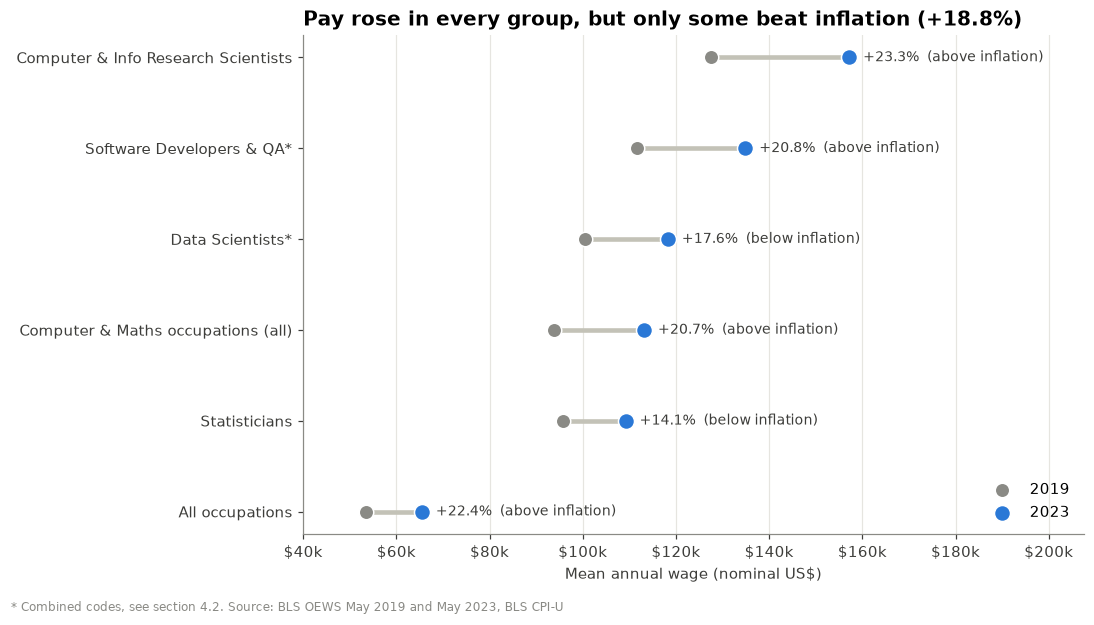

In [143]:
CPI_MAY_2019, CPI_MAY_2023 = 256.092, 304.127      # CPI-U, all items, 1982-84=100 (BLS)
inflation = CPI_MAY_2023 / CPI_MAY_2019 - 1

w = trend.pivot(index="group", columns="year", values="a_mean")[[2019, 2023]]
w["pct"] = w[2023] / w[2019] - 1
w = w.sort_values(2023)

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(w))
ax.hlines(y, w[2019], w[2023], color="#c3c2b7", linewidth=3, zorder=1)
ax.scatter(w[2019], y, s=90, color=GREY, label="2019", zorder=3, edgecolor="white")
ax.scatter(w[2023], y, s=110, color=CAT_COLOURS["AI & Data Science"], label="2023", zorder=3, edgecolor="white")
for i, (name, r) in enumerate(w.iterrows()):
    beat = "above" if r["pct"] > inflation else "below"
    ax.text(r[2023] + 3000, i, f"{r['pct']:+.1%}  ({beat} inflation)", va="center", fontsize=9, color=INK)
ax.set_yticks(y); ax.set_yticklabels(w.index)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))
ax.set_xlim(40000, w[2023].max() * 1.32)
ax.set_xlabel("Mean annual wage (nominal US$)")
ax.set_title(f"Pay rose in every group, but only some beat inflation ({inflation:+.1%})")
ax.legend(loc="lower right")
ax.grid(axis="x"); ax.set_axisbelow(True)
fig.text(0.01, -0.02, "* Combined codes, see section 4.2. Source: BLS OEWS May 2019 and May 2023, BLS CPI-U",
         fontsize=8, color=GREY)
plt.tight_layout()
plt.show()

**What I learned about AI employment over time:**

* **Computer and Information Research Scientists** had the biggest pay increase, about **+23%**, reaching an average of more than **$157,000**. This is above inflation, so their **real** pay went up. Demand for advanced AI research skills pushed pay up faster than the rest of the market.
* **Software Developers and QA** rose about **+21%**, slightly above inflation. **Data Scientists** (about **+18%**) and **Statisticians** (about **+14%**) rose **less than inflation**, so their real pay fell a little. For Data Scientists, employment grew very fast (Visualisation 7) but average pay did not grow as fast. A likely reason is that many of the new data scientists are junior hires, which keeps the average down.
* The average for **all US occupations** rose about **22%**, partly because many low paid jobs disappeared in 2020 and 2021, which raises the average. So high growth in tech pay is a strong but not unique trend.

### Visualisation 9: Share of US jobs in AI and data roles (column chart)

**Objective:** *change in proportion over time.* Measure whether AI and data roles are becoming a bigger part of the US economy, not only growing in absolute numbers.

**Why this chart:** the variable is a **ratio for each year** (five discrete years). Columns make each year's value easy to compare and to read directly. The measure used is Data Scientists plus Computer and Information Research Scientists **per 10,000 US jobs**, which removes the effect of the total labour market getting bigger or smaller. 2019 and 2020 are shown in a lighter colour to remind the reader of the classification change.

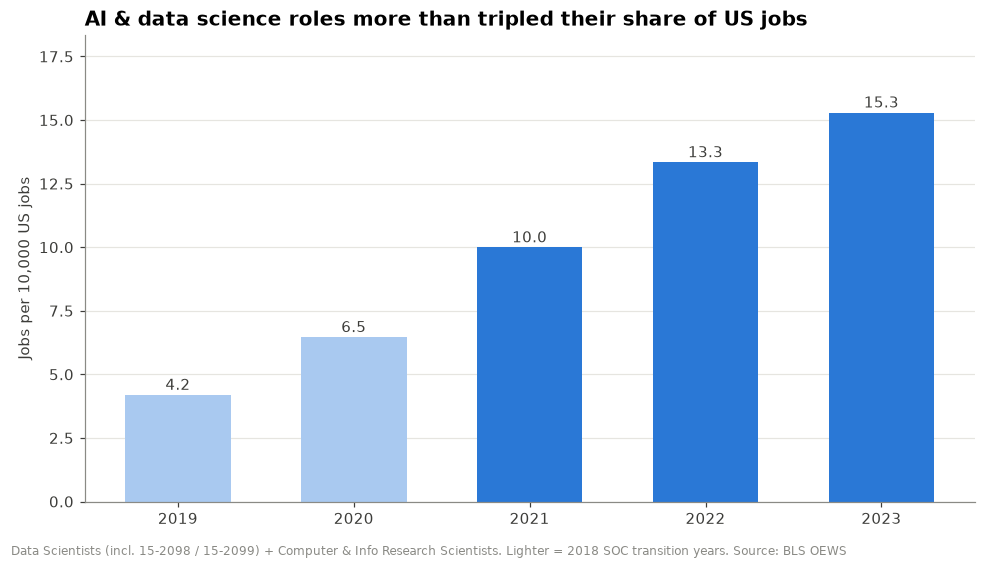

year
2019     4.19
2020     6.46
2021     9.99
2022    13.34
2023    15.29


In [144]:
ai_core = (trend[trend["group"].isin(["Data Scientists*", "Computer & Info Research Scientists"])]
           .groupby("year")["tot_emp"].sum())
total = trend[trend["group"] == "All occupations"].set_index("year")["tot_emp"]
per10k = ai_core / total * 10000

fig, ax = plt.subplots(figsize=(9, 5))
colours = ["#a9c9f0" if yr < 2021 else CAT_COLOURS["AI & Data Science"] for yr in per10k.index]
bars = ax.bar(per10k.index.astype(str), per10k.values, color=colours, width=0.6)
for b, v in zip(bars, per10k.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.2, f"{v:.1f}", ha="center", fontsize=10, color=INK)
ax.set_ylabel("Jobs per 10,000 US jobs")
ax.set_ylim(0, per10k.max() * 1.2)
ax.set_title("AI & data science roles more than tripled their share of US jobs")
ax.grid(axis="y"); ax.set_axisbelow(True)
fig.text(0.01, -0.02, "Data Scientists (incl. 15-2098 / 15-2099) + Computer & Info Research Scientists. "
         "Lighter = 2018 SOC transition years. Source: BLS OEWS", fontsize=8, color=GREY)
plt.tight_layout()
plt.show()

print(per10k.round(2).to_string())

**What I learned about AI employment over time:**

* In 2019 only about **4** in every 10,000 US jobs were Data Scientists or Computer and Information Research Scientists. By 2023 it was about **15** in 10,000.
* Even using only the reliable 2021 to 2023 period, the share grew from about **10** to about **15** per 10,000 jobs, a rise of roughly **50% in two years**. AI and data roles are not only growing, they are taking a **larger share of the whole economy**.
* The numbers are still small in absolute terms (about 0.15% of all jobs), which shows that AI specialist work is a fast growing **niche**. Most of the impact of AI on employment probably happens inside other occupations, which this dataset cannot measure directly.

## 5. Conclusions

1. **Size:** in May 2023 the core AI & Data Science occupations employed about **376,000** people in the USA, compared with about **1.66 million** Software Developers. Data Scientists are the largest AI specific occupation.
2. **Pay:** all AI, data and software occupations pay well above the US median. Specialist AI research roles pay the most, which reflects a scarcity of advanced skills.
3. **Location:** AI jobs are concentrated in a few places, especially the San Francisco Bay Area, Washington state, Massachusetts and the Washington DC area, with growing secondary hubs such as Austin, Denver and Utah.
4. **Industry:** Data Scientists work across the whole economy, mainly in professional services and finance, not only in technology companies.
5. **Trend:** between 2021 and 2023 the number of Data Scientists grew by about **79%**, much faster than software development (about **20%**) and the total labour market (about **8%**). The share of US jobs in core AI roles has grown every year since 2019.

## 6. Limitations

* There is no official "AI" occupation code, so the chosen occupations are a **proxy**. Some of these workers do not work on AI, and many people who use AI are classified in other occupations.
* OEWS estimates come from a **survey** and have sampling error (see the `EMP_PRSE` column). They also **exclude self employed** workers, such as freelancers.
* The 2018 SOC change makes 2019 and 2020 not fully comparable with later years (section 4.2).
* Wages are **nominal**. Inflation is only used as a reference in Visualisation 8.

## 7. References

Bureau of Labor Statistics (2019) *Consumer Price Index: May 2019* (USDL-19-1013). Washington, DC: U.S. Department of Labor. Available at: https://www.bls.gov/news.release/archives/cpi_06122019.pdf (Accessed: 6 November 2026).

Bureau of Labor Statistics (2020) *May 2019 National Occupational Employment and Wage Estimates, United States*. Available at: https://www.bls.gov/oes/2019/may/oes_nat.htm (Accessed: 6 November 2026).

Bureau of Labor Statistics (2021) *May 2020 National Occupational Employment and Wage Estimates, United States*. Available at: https://www.bls.gov/oes/2020/may/oes_nat.htm (Accessed: 6 November 2026).

Bureau of Labor Statistics (2022) *May 2021 National Occupational Employment and Wage Estimates, United States*. Available at: https://www.bls.gov/oes/2021/may/oes_nat.htm (Accessed: 6 November 2026).

Bureau of Labor Statistics (2023a) *May 2022 National Occupational Employment and Wage Estimates, United States*. Available at: https://www.bls.gov/oes/2022/may/oes_nat.htm (Accessed: 6 November 2026).

Bureau of Labor Statistics (2023b) *Consumer Price Index: May 2023* (USDL-23-1290). Washington, DC: U.S. Department of Labor. Available at: https://www.bls.gov/news.release/archives/cpi_06132023.pdf (Accessed: 6 November 2026).

Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics: May 2023 All data* [Dataset]. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 6 November 2026).

Hunter, J.D. (2007) 'Matplotlib: A 2D graphics environment', *Computing in Science & Engineering*, 9(3), pp. 90 to 95.

McKinney, W. (2010) 'Data structures for statistical computing in Python', *Proceedings of the 9th Python in Science Conference*, pp. 56 to 61.

Waskom, M.L. (2021) 'seaborn: statistical data visualization', *Journal of Open Source Software*, 6(60), p. 3021.

